# 실습 ① 데이터 추출 및 분할 — 연습본

> **[권장 난이도: 초급]** · **[추천 소요 시간: 50분]** · **[교육 과정: 12~13주차 · 4교시]**

PDF 한 편을 **텍스트 / 표 / 이미지** 세 종류로 분리합니다. 멀티모달 RAG의 출발점입니다.

---

## 오늘 만드는 것

```
PDF 문서  ──▶  Unstructured Parser  ──▶  텍스트 / 표 / 이미지
```

## 진행 방법

1. 셀을 **위에서부터 순서대로** 실행합니다 (`Shift + Enter`)
2. `# TODO` 와 `____` 가 있는 곳을 직접 채웁니다
3. 각 단계의 **확인 포인트**를 통과하면 다음으로 넘어갑니다
4. 막히면 바로 손을 드세요. 혼자 10분 이상 붙잡고 있지 마세요

## 완료 기준

- [ ] `figures/` 폴더에 `.jpg` 파일이 생성된다
- [ ] 텍스트 블록 수가 0보다 크다
- [ ] 추출된 이미지를 눈으로 확인했다

## 0. 환경 검증

> ⚠️ **하나라도 ✗가 있으면 진행하지 말고 손을 드세요.**

In [1]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()

# OS 패키지 확인 (pip로 설치되지 않는 것들)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
print()

# 파이썬 패키지 확인
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치")

Python: 3.11.9
가상환경 경로: c:\workspaces\multimodal-rag2\.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK


## 1. 라이브러리 임포트

아래 셀을 그대로 실행하세요.

| 라이브러리 | 역할 |
| --- | --- |
| `partition_pdf` | PDF를 텍스트·표·이미지로 분리하는 **자동 분리수거 기계** |
| `CharacterTextSplitter` | 긴 텍스트를 일정 크기로 자르는 **작두** |

In [2]:
%pip install unstructured-inference

  Using cached unstructured_inference-1.6.17-py3-none-any.whl.metadata (5.7 kB)
  Using cached accelerate-1.15.0-py3-none-any.whl.metadata (19 kB)
  Using cached onnx-1.23.2-cp311-cp311-win_amd64.whl.metadata (8.7 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached timm-1.0.31-py3-none-any.whl.metadata (42 kB)
  Using cached transformers-5.22.1-py3-none-any.whl.metadata (31 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached ml_dtypes-0.6.0-cp311-cp311-win_amd64.whl.metadata (8.8 kB)
  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
Using cached unstructured_inference-1.6.17-py3-none-any.whl (58 kB)
Using cached accelerate-1.15.0-py3-none-any.whl (394 kB)
Using cached onnx-1.23.2-cp311-cp311-win_amd64.whl (7.9 MB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Using cached scipy-1.


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import time
import pickle
from pathlib import Path

from langchain_text_splitters import CharacterTextSplitter
from unstructured.partition.pdf import partition_pdf

print("임포트 완료")

임포트 완료


## 2. 경로 설정

**TODO 1.** `fname`에 본인이 준비한 PDF 파일 이름을 적으세요.

> ⚠️ **윈도우 주의:** 경로에 한글이나 공백이 들어가면 뒤에서 오류가 납니다.

In [7]:
# 노트북은 notebooks/ 안에서 실행되므로, 프로젝트 루트는 그 부모 폴더
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# TODO 1: 본인의 PDF 파일 이름으로 바꾸세요.
fname = "economy2024.pdf"

pdf_dir = PROJECT_ROOT / "data"          # 원본 PDF 폴더
pdf_path = pdf_dir / fname
fpath = str(pdf_dir) + os.sep            # 추출 함수에 path + fname 으로 넘기기 위함

# 추출된 이미지는 항상 <프로젝트 루트>/data/figures 에 저장
figures_dir = PROJECT_ROOT / "data" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

print("현재 위치     :", Path.cwd())
print("프로젝트 루트  :", PROJECT_ROOT)
print("PDF 경로      :", pdf_path.resolve())
print("PDF 존재 여부  :", pdf_path.exists())
print("이미지 저장폴더:", figures_dir.resolve())

현재 위치     : c:\workspaces\multimodal-rag2\notebooks
프로젝트 루트  : c:\workspaces\multimodal-rag2
PDF 경로      : C:\workspaces\multimodal-rag2\data\economy2024.pdf
PDF 존재 여부  : True
이미지 저장폴더: C:\workspaces\multimodal-rag2\data\figures


> ✅ **확인 포인트:** `PDF 존재 여부`가 `True`여야 합니다. `False`면 다음 셀은 반드시 실패합니다.

## 3. 추출 함수 만들기

**TODO 2~4.** 빈칸 3개를 채우세요.

| 옵션 | 하는 일 | 빼면 생기는 일 |
| --- | --- | --- |
| `strategy` | 레이아웃 분석 모델로 정밀 추출 | 표·이미지 추출 정확도 급락 |
| `extract_images_in_pdf` | 그림을 별도 파일로 저장 | 이미지가 통째로 사라짐 |
| `infer_table_structure` | 표의 행·열 구조를 추론 | 표가 줄글로 뭉개짐 |

💡 **힌트**
- TODO 2: 정밀 추출 전략의 이름입니다. "high resolution"의 줄임말이에요 (문자열)
- TODO 3: 이미지를 꺼내야 멀티모달이 됩니다 (True / False)
- TODO 4: 표의 구조도 알아내야겠죠 (True / False)

In [8]:
def extract_pdf_elements(path, fname):
    """
    PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다.

    path : 파일 경로 (추출된 이미지 파일이 저장될 위치)
    fname: 파일 이름
    """
    # 추출 이미지는 <프로젝트 루트>/data/figures 에 저장
    figures_dir = PROJECT_ROOT / "data" / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)

    return partition_pdf(
        filename=path + fname,
        strategy="hi_res",
        extract_images_in_pdf=True,
        infer_table_structure=True,
        chunking_strategy="by_title",
        max_characters=4000,
        new_after_n_chars=3800,
        combine_text_under_n_chars=2000,
        extract_image_block_output_dir=str(figures_dir),
    )

print("extract_pdf_elements 정의 완료")

extract_pdf_elements 정의 완료


## 4. 요소 분류 함수 만들기

추출된 요소를 **텍스트**와 **표** 두 리스트로 나눕니다.

**TODO 5~6.** 어느 리스트에 담아야 할지 채우세요.

💡 **힌트:** 바로 위 `if` 조건문에 무엇이 들어 있는지 보세요. `Table`이면 어디로, `CompositeElement`(텍스트 덩어리)면 어디로 가야 할까요?

In [9]:
def categorize_elements(raw_pdf_elements):
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.

    raw_pdf_elements: unstructured.documents.elements 리스트
    """

    tables = []
    texts = []

    for element in raw_pdf_elements:
        if "unstructured.documents.elements.Table" in str(type(element)):
            tables.append(str(element))       # TODO 5: 표는 tables 리스트
        elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
            texts.append(str(element))        # TODO 6: 텍스트는 texts 리스트

    return texts, tables


print("categorize_elements 정의 완료")

categorize_elements 정의 완료


## 5. 추출 실행

> ⏱️ **이 셀은 2~3분 걸립니다. 멈춘 것이 아니니 기다리세요.**
>
> 왼쪽 대괄호가 `[*]` 상태면 실행 중이라는 뜻입니다. 숫자로 바뀌면 완료입니다.

In [10]:
start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname)

print(f"추출 완료 — {time.time() - start:.1f}초 소요")
print("추출된 전체 요소 수:", len(raw_pdf_elements))

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
No languages specified, defaulting to English.
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 1581.00it/s]


추출 완료 — 172.6초 소요
추출된 전체 요소 수: 21


In [11]:
texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수    :", len(tables))

텍스트 블록 수: 15
표 블록 수    : 6


> ✅ **확인 포인트:** `텍스트 블록 수`가 0보다 커야 합니다.
>
> 📌 `표 블록 수`가 0이어도 괜찮습니다. PDF 안의 표가 **이미지로 그려진** 경우에는 표로 잡히지 않습니다.

## 6. 어떤 요소들이 나왔는지 집계

**TODO 7.** 집계 결과를 보고 아래 질문에 답해 보세요.

- 내 PDF에서 가장 많이 나온 요소 타입은 무엇인가?
- `Table`이 잡혔는가? 안 잡혔다면 왜일까?

In [12]:
from collections import Counter

type_counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in type_counts.most_common():
    print(f"{element_type:22s}: {count}개")

CompositeElement      : 15개
Table                 : 6개


**TODO 7 답을 여기에 적으세요 (더블클릭해서 편집)**

- 가장 많이 나온 요소 타입:CompositeElement와 15개
- Table이 잡혔는가?:잡혔다. 총 6개의 Table 요소가 추출되었다.
- 그 이유는: strategy="hi_res"를 사용하여 PDF의 레이아웃을 분석하고 표 영역을 인식했으며, infer_table_structure=True 설정을 통해 표 구조를 추론했기 때문이다.

## 7. 추출된 이미지 확인

> 📌 **이 단계를 건너뛰지 마세요.** `figures/` 폴더를 **직접 열어서** 그림이 진짜로 나왔는지 눈으로 확인해야 합니다.

In [13]:
figures_dir = PROJECT_ROOT / "data" / "figures"

if figures_dir.exists():
    image_files = sorted(
        f for f in figures_dir.iterdir()
        if f.suffix.lower() in (".jpg", ".jpeg", ".png")
    )

    print(f"추출된 이미지: {len(image_files)}개\n")

    for f in image_files[:10]:
        print(f"  {f.name}  ({f.stat().st_size // 1024} KB)")
else:
    print("figures 폴더가 없습니다.")

추출된 이미지: 83개

  figure-1-1.jpg  (97 KB)
  figure-10-12.jpg  (44 KB)
  figure-10-13.jpg  (37 KB)
  figure-10-14.jpg  (6 KB)
  figure-12-15.jpg  (43 KB)
  figure-12-16.jpg  (43 KB)
  figure-12-17.jpg  (6 KB)
  figure-13-18.jpg  (42 KB)
  figure-14-19.jpg  (44 KB)
  figure-15-20.jpg  (47 KB)


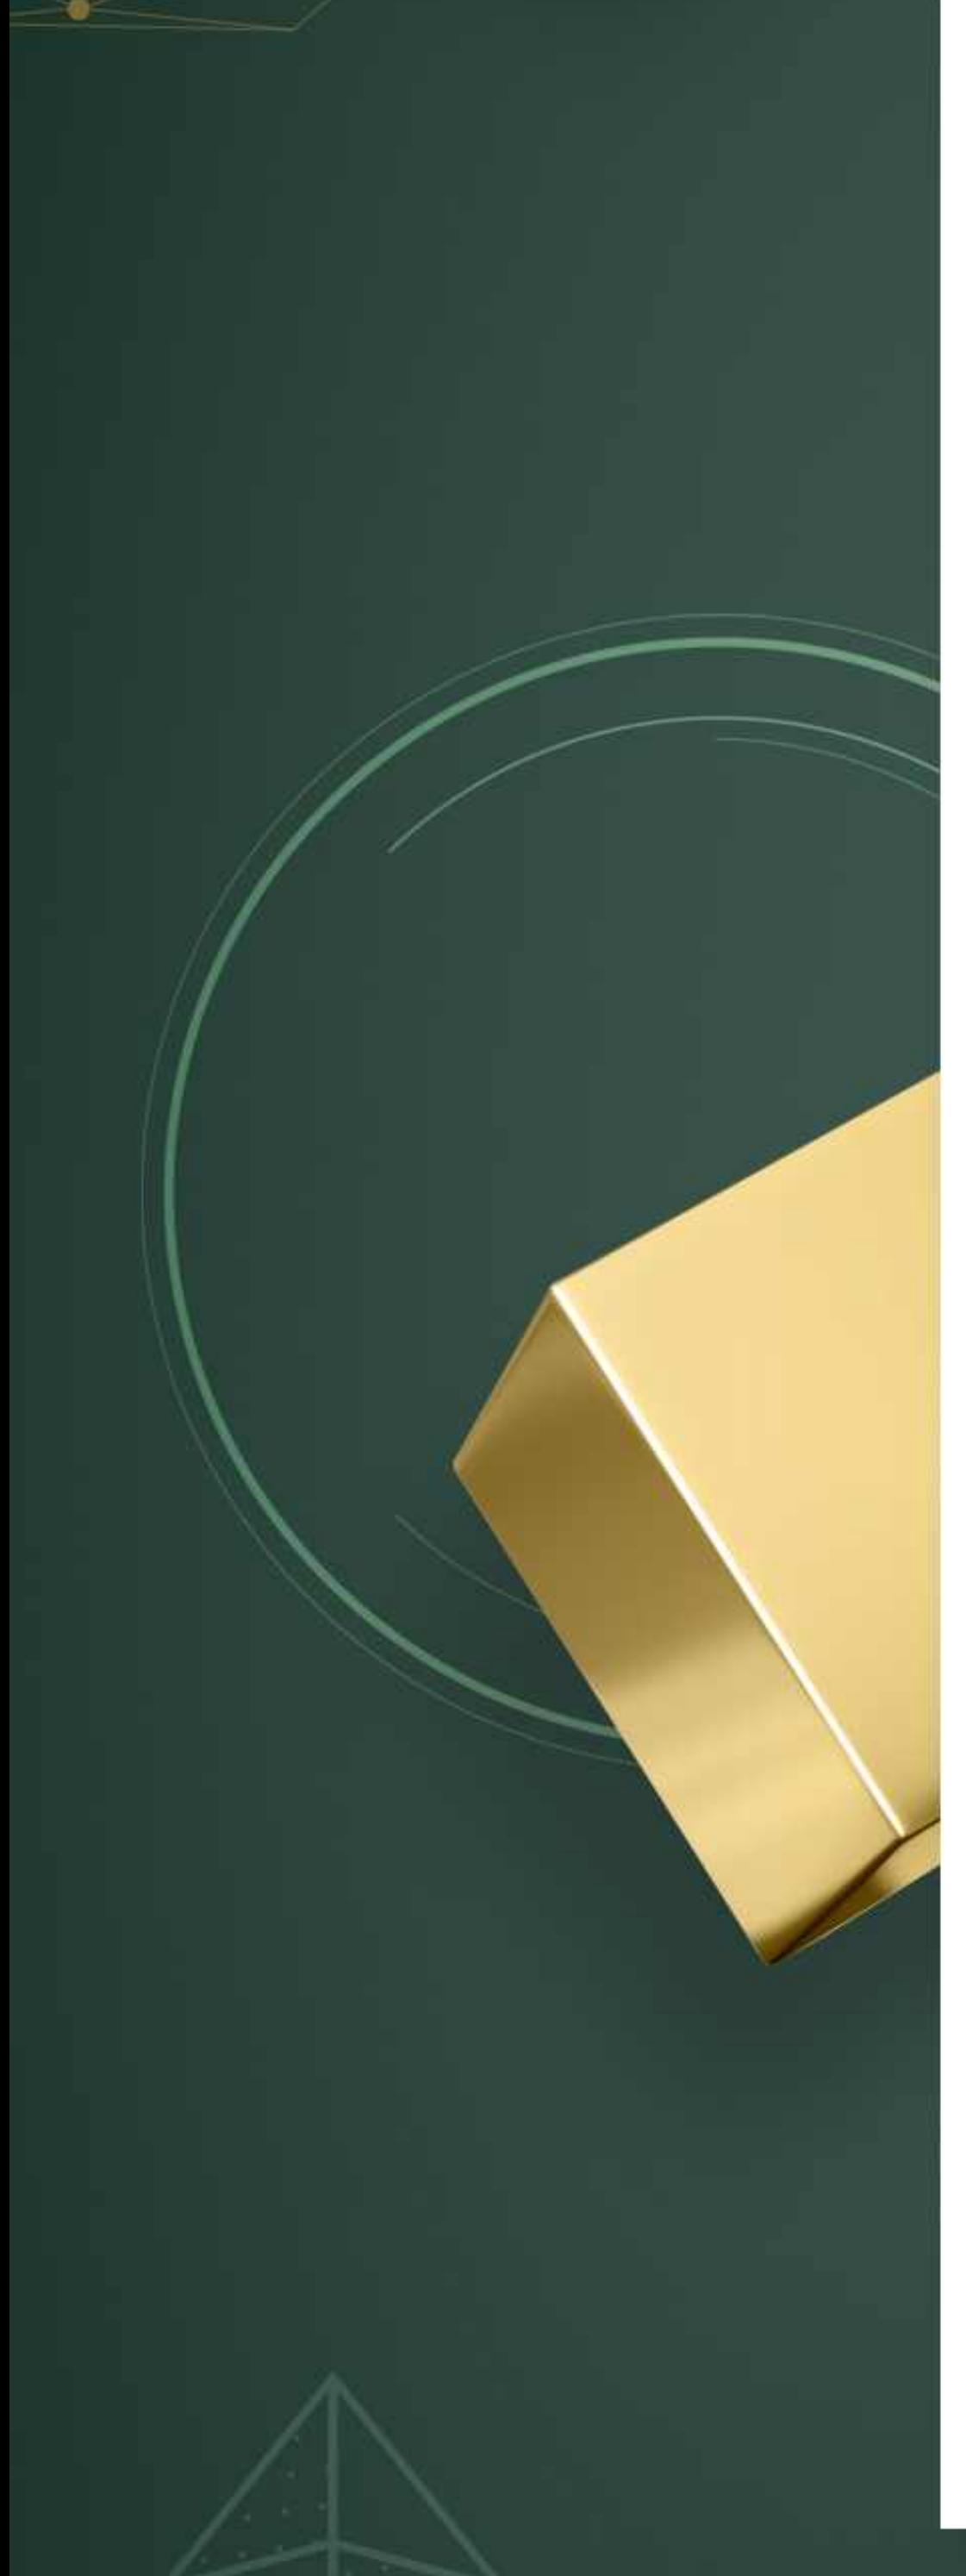

In [14]:
# 첫 번째 이미지를 노트북에서 직접 확인
from IPython.display import Image, display

if figures_dir.exists() and image_files:
    display(Image(filename=str(image_files[0]), width=500))
else:
    print("표시할 이미지가 없습니다.")

> ✅ **확인 포인트:** 이미지가 화면에 보이면 성공입니다. 안 보이면 `figures/` 폴더가 비어 있다는 뜻이니 TODO 2, 3을 확인하세요.

## 8. 텍스트 분할

추출된 텍스트를 **2000자 단위로 다시 자릅니다.**

**TODO 8.** 겹침(overlap) 값을 채우세요.

💡 **힌트:** 문장이 블록 경계에서 잘려 뜻이 사라지는 것을 막기 위해 앞뒤를 조금씩 겹치게 자릅니다. 교재 기준값은 **200**입니다.

In [15]:
text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,       # 각 텍스트 블록의 최대 크기
    chunk_overlap=200,    # TODO 8: 청크 간 겹칠 글자 수
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수  :", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print("전체 글자 수  :", len(joined_texts))

원본 블록 수  : 15
분할 후 블록 수: 34
전체 글자 수  : 33890


## 9. 분할 결과 비교

원본과 분할된 텍스트의 첫 번째 요소를 비교합니다.

In [16]:
print("=" * 60)
print("[원본 texts[0]] 앞 300자")
print("=" * 60)
print(texts[0][:300])
print()

print("=" * 60)
print("[분할 texts_2k_token[0]] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])

[원본 texts[0]] 앞 300자
24-09(통권 967호) 2024.06.05

oM=S

2024년 한국 경제 전망(수정) - 2024년 경제성장률, 0.5%p 상향조정한 2.7%

목 차

v

■ 2024년 한국 경제 전망(수정) - 2024년 경제성장률, 0.5%p 상향조정한 2.7% Executive Summary ······················································································ⅰ 1. 대외 경제 환경 변화 ·································

[분할 texts_2k_token[0]] 앞 300자
24-09(통권 967호) 2024.06.05

oM=S

2024년 한국 경제 전망(수정) - 2024년 경제성장률, 0.5%p 상향조정한 2.7%

목 차

v

■ 2024년 한국 경제 전망(수정) - 2024년 경제성장률, 0.5%p 상향조정한 2.7% Executive Summary ······················································································ⅰ 1. 대외 경제 환경 변화 ·································


## 10. 다음 교시를 위한 저장

추출에 2~3분이 걸리므로 결과를 파일로 저장해 둡니다. 5교시에서 그대로 불러 씁니다.

In [17]:
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "extracted.pkl", "wb") as f:
    pickle.dump(
        {"texts": texts, "tables": tables, "texts_2k_token": texts_2k_token},
        f,
    )

print("저장 완료:", output_dir / "extracted.pkl")

저장 완료: c:\workspaces\multimodal-rag2\data\processed\extracted.pkl


---

## ✅ 체크포인트 1 — 모두 체크되면 4교시 완료

- [x] `figures/` 폴더가 생기고 그 안에 `.jpg` 파일이 있다
- [x] `len(texts)`와 `len(texts_2k_token)`이 둘 다 0보다 크다
- [x] 폴더를 직접 열어 추출된 그림을 **눈으로** 확인했다
- [x] `data/processed/extracted.pkl` 파일이 생성되었다
- [x] TODO 1~8을 모두 채웠다

## 생각해 볼 질문 (답을 적어보세요)

더블클릭해서 편집하세요. 정답을 맞히는 것보다 **본인 말로 써 보는 것**이 중요합니다.

**Q1. `strategy="hi_res"`를 빼면 왜 표와 이미지가 잘 안 잡힐까요?**

답:hi_res는 고해상도 이미지 분석과 레이아웃 분석을 통해 PDF의 표, 이미지, 제목, 문단 등의 구조를 파악하는 전략입니다. 이를 사용하지 않으면 기본 텍스트 추출 방식으로 처리되어 표의 행과 열 구조나 이미지와 같은 시각적 요소를 제대로 인식하지 못할 수 있습니다.

**Q2. 텍스트를 자를 때 왜 200자를 겹치게 할까요? 겹치지 않으면 어떤 일이 생길까요?**

답:청크를 나눌 때 문맥이 끊기는 것을 방지하고 앞뒤 내용의 연관성을 유지하기 위해 200자를 겹치게 합니다. 겹치지 않으면 문장이나 중요한 정보가 청크 경계에서 분리되어 검색 시 필요한 문맥을 놓치거나 답변의 정확도가 떨어질 수 있습니다.

**Q3. 지금 단계에서 이미지는 파일로 저장만 되어 있습니다. 이 상태로는 검색이 안 되는데, 왜 그럴까요?**

답:이미지는 파일 형태로 저장되어 있을 뿐, 이미지 안에 포함된 내용이 텍스트 데이터로 변환되거나 벡터화되지 않았기 때문입니다. 따라서 텍스트 기반 검색 시스템은 이미지의 내용을 이해하거나 검색할 수 없습니다. OCR이나 이미지 캡셔닝 등을 통해 이미지의 내용을 텍스트로 변환한 후 임베딩하여 벡터 DB에 저장해야 검색할 수 있습니다.

## 자주 나는 에러

| 증상 | 원인 | 해결 |
| --- | --- | --- |
| `PDFInfoNotInstalledError` | Poppler 미설치 / Path 누락 | 설치 후 **커널 재시작** |
| `TesseractNotFoundError` | Tesseract Path 누락 | `C:\Program Files\Tesseract-OCR` 추가 후 재시작 |
| `FileNotFoundError` | PDF 파일명/경로 오류 | TODO 1과 `PDF 존재 여부` 확인 |
| `figures/`가 비어 있음 | TODO 2, 3 미완성 | 두 옵션 모두 확인 |
| `NameError: texts` | 앞 셀을 안 돌림 | 위에서부터 순서대로 재실행 |
| 파싱이 끝나지 않음 | 정상. `hi_res`는 느림 | 2~3분 대기 |

> 그래도 안 되면 **커널 재시작 후 위에서부터 전체 재실행**하세요. 변수가 꼬여 생기는 오류가 의외로 많습니다.